# Experimento 8 — Nostalgia: a idade no lançamento melhora a previsão?

**Pergunta de partida.** Com os onze atributos (experimento 7, notebook 10), o boosting (RMSE ≈ 0,545) supera a regressão (≈ 0,615) por cerca de 0,07 estrela. O enunciado pede para explicar **por que** o modelo final supera a regressão. Dizer que "o boosting captura não linearidades" não basta. Queremos saber **qual** estrutura ele aprende que a regressão não representa.

**Hipótese:** usuários dão notas mais altas a filmes lançados quando eram adolescentes. Isso é uma **interação** entre `age` e `release_year`: o efeito do ano de lançamento depende da idade do usuário. Na receita atual, idade e ano entram separados (idade linear, ano linear e quadrático), então um modelo aditivo não consegue representar esse efeito.

**Roteiro**
1. Descobrir quais interações o boosting usa, restringindo as interações permitidas.
2. Construir a variável *idade no lançamento* e olhar a nota média por faixa.
3. Representar o pico de nostalgia num atributo que a regressão consiga usar.
4. Avaliar com validação aninhada (`src/nostalgia_test.py`) e teste t corrigido.

**Protocolo:** 5 dobras × 5 repetições, semente 2026, as mesmas partições dos experimentos anteriores, apenas `train.csv`, previsões cortadas em [0, 5]. Centro e largura do pico, e os hiperparâmetros do boosting, são escolhidos em 3 folds internos de cada treino externo.

A hipótese surgiu da exploração destes mesmos dados, depois de olharmos o boosting. Por isso o resultado é exploratório, não uma confirmação independente.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import RepeatedKFold

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data' / 'train.csv').exists())
sys.path.insert(0, str(ROOT))

from src.final_feature_tests import BOOST_FIXED
from src.final_submission import FEATURES, SEED, add_features, clipped_rmse
from src.nostalgia_test import AGE_AT_RELEASE, REFERENCE_YEAR, add_age_at_release

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
df = add_age_at_release(add_features(pd.read_csv(ROOT / 'data' / 'train.csv')))
y = df['stars'].to_numpy(dtype=float)
folds = list(RepeatedKFold(n_splits=5, n_repeats=5, random_state=SEED).split(df))
print(df.shape, len(folds), 'partições')

(4000, 21) 25 partições


## 1. Que interações o boosting usa?

O `HistGradientBoostingRegressor` aceita o parâmetro `interaction_cst`, que diz quais atributos podem aparecer **juntas numa mesma árvore**. Se proibirmos todas as interações, o boosting vira um modelo **aditivo**: a soma de uma curva para cada atributo, sem combinações entre elas. Depois liberamos **um único par** de atributos por vez e vemos quanto o erro cai. O par que mais reduz o erro é a interação mais importante.

Para comparar só a estrutura, os hiperparâmetros ficam fixos (15 folhas, mínimo de 20 por folha).

In [2]:
index = {name: i for i, name in enumerate(FEATURES)}
X = df[FEATURES].to_numpy(dtype=float)
GENRE = ['genre_comedy', 'genre_drama']
AFFINITY = ['affinity', 'affinity2']
YEAR = ['release_year_scaled', 'release_year_squared']

def boosting_rmse(groups):
    # Atributos de um mesmo grupo podem interagir; os demais entram sozinhos.
    used = sum(groups, [])
    constraints = [[index[c] for c in g] for g in groups] + [[index[c]] for c in FEATURES if c not in used]
    scores = []
    for train, valid in folds:
        model = HistGradientBoostingRegressor(**BOOST_FIXED, max_leaf_nodes=15, min_samples_leaf=20,
                                              interaction_cst=constraints)
        scores.append(clipped_rmse(y[valid], model.fit(X[train], y[train]).predict(X[valid])))
    return np.mean(scores)

configs = {
    'aditivo (nenhuma interação)': [],
    'só idade × ano': [['age'] + YEAR],
    'só gênero × idade': [GENRE + ['age']],
    'só gênero × ano': [GENRE + YEAR],
    'só afinidade × gênero': [AFFINITY + GENRE],
    'só duas médias × afinidade': [['user_avg_stars', 'movie_avg_stars'] + AFFINITY],
    'todas as interações (boosting comum)': [FEATURES],
}
interactions = pd.Series({name: boosting_rmse(g) for name, g in configs.items()}, name='E_CV')
interactions.to_frame()

,E_CV
aditivo (nenhuma interação),0.639035
só idade × ano,0.601477
só gênero × idade,0.635824
só gênero × ano,0.636427
só afinidade × gênero,0.631233
só duas médias × afinidade,0.630485
todas as interações (boosting comum),0.543992


**Leitura**
- O boosting **aditivo** é pior que o boosting comum. Grande parte da vantagem do boosting vem de **interações**, não de curvas em atributos isolados.
- Entre os pares testados, **idade × ano** é, de longe, o que mais reduz o erro. As interações com gênero e com as médias ajudam bem menos.

## 2. A idade no lançamento

Se o efeito depende de idade e ano juntos, uma combinação natural é a **idade que o usuário tinha quando o filme foi lançado**:

$$\text{idade no lançamento} = \text{age} - (2024 - \text{release\_year}).$$

O ano de referência (2024, o último lançamento dos dados) só desloca a escala. Valores negativos indicam filmes lançados antes de o usuário nascer.

,nota média,pares
age_at_release,,
"(-70, -20]",3.251256,199
"(-20, -10]",3.301158,259
"(-10, 0]",3.191710,386
"(0, 5]",3.448630,292
"(5, 10]",3.689349,338
"(10, 15]",4.041451,386
"(15, 20]",3.913580,405
"(20, 25]",3.574307,397
"(25, 30]",3.230263,304


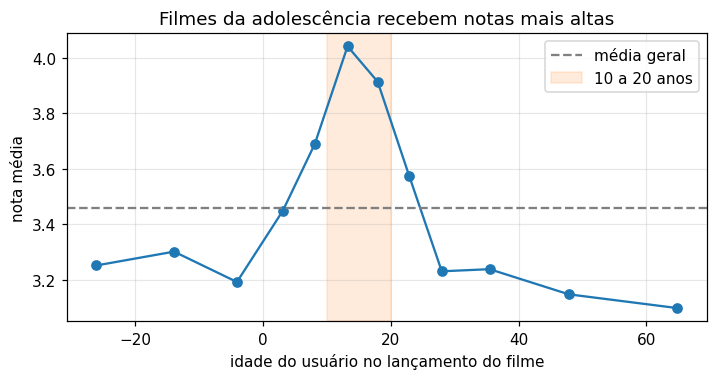

In [3]:
faixas = pd.cut(df[AGE_AT_RELEASE], [-70, -20, -10, 0, 5, 10, 15, 20, 25, 30, 40, 60, 90])
tabela = df.groupby(faixas, observed=True)['stars'].agg(['mean', 'count'])
tabela.columns = ['nota média', 'pares']
display(tabela)

fig, ax = plt.subplots(figsize=(7.5, 3.4))
centros = df.groupby(faixas, observed=True)[AGE_AT_RELEASE].mean()
ax.plot(centros, tabela['nota média'], 'o-')
ax.axhline(y.mean(), color='gray', ls='--', label='média geral')
ax.axvspan(10, 20, color='C1', alpha=0.15, label='10 a 20 anos')
ax.set(xlabel='idade do usuário no lançamento do filme', ylabel='nota média',
       title='Filmes da adolescência recebem notas mais altas')
ax.legend()
plt.show()

**Leitura:** há um **pico** claro. Quem tinha entre 10 e 20 anos no lançamento dá em média cerca de 4 estrelas, contra cerca de 3,2 nas demais faixas. O efeito não é linear: sobe até a adolescência e depois desce.

Isso explica por que idade e ano, **separados**, ajudavam pouco a regressão (0,625 → 0,616). Um mesmo ano de lançamento é "da adolescência" para uns usuários e "de antes de nascer" para outros. Visto isoladamente, o ano tem efeito médio fraco.

## 3. Um atributo que a regressão consiga usar

A regressão linear só soma atributos multiplicados por pesos. Para que ela represente um pico, precisamos **construir** um atributo com esse formato. Usamos uma curva em forma de sino:

$$\text{nostalgia} = \exp\left(-\frac{(\text{idade no lançamento} - c)^2}{2 w^2}\right),$$

que vale 1 quando a idade no lançamento é igual ao centro $c$ e cai para 0 à medida que se afasta dele. A largura $w$ controla quão rápido ela cai. **Centro e largura são hiperparâmetros**: em cada partição externa, eles são escolhidos por validação cruzada interna, só com a parte de treino (`NostalgiaBump` em `src/nostalgia_test.py`).

O boosting não precisa do formato pronto. Basta lhe dar a **idade no lançamento** como atributo, e as árvores aprendem o pico sozinhas com alguns cortes.

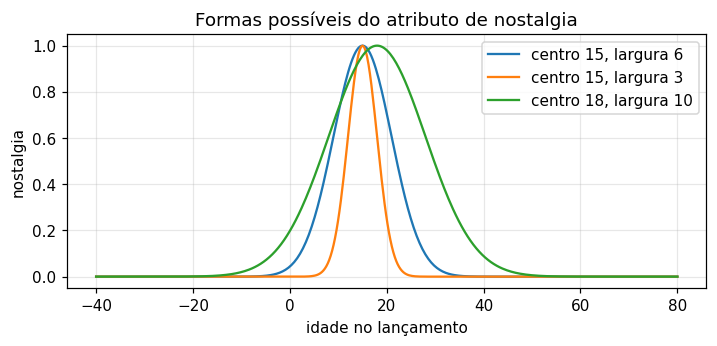

In [4]:
x = np.linspace(-40, 80, 400)
fig, ax = plt.subplots(figsize=(7.5, 3))
for c, w in [(15, 6), (15, 3), (18, 10)]:
    ax.plot(x, np.exp(-((x - c) ** 2) / (2 * w ** 2)), label=f'centro {c}, largura {w}')
ax.set(xlabel='idade no lançamento', ylabel='nostalgia', title='Formas possíveis do atributo de nostalgia')
ax.legend()
plt.show()

## 4. Resultado com validação aninhada

O cálculo completo (25 partições, com as buscas internas) está em `src/nostalgia_test.py`. Ele demora alguns minutos e grava os resultados em `results/rodada_atual/teste_nostalgia*.csv`. Aqui lemos esses arquivos.

```bash
python -m src.nostalgia_test
```

In [5]:
results = ROOT / 'results' / 'rodada_atual'
summary = pd.read_csv(results / 'teste_nostalgia.csv').set_index('modelo')
display(summary.round(6))

tests = pd.read_csv(results / 'teste_nostalgia_comparacoes.csv').set_index('comparação')
display(tests[['diferença média', 'IC inferior', 'IC superior', 'p-valor', 'vitórias de a']].round(6))

selections = pd.read_csv(results / 'teste_nostalgia_selecoes.csv')
bump = selections[selections['modelo'] == 'Regressão 11 atributos + nostalgia']
print('centro e largura escolhidos nas 25 partições:')
display(bump.groupby(['nostalgia__center', 'nostalgia__width']).size().rename('partições').to_frame())

,RMSE OOF repetido,E_CV,desvio_E_CV,E_in
modelo,,,,
Regressão 11 atributos,0.615210,0.615032,0.015099,0.612450
Regressão 11 atributos + nostalgia,0.541704,0.541559,0.012832,0.539054
Boosting 11 atributos,0.544933,0.544753,0.014287,0.431541
Boosting 11 atributos + idade no lançamento,0.519532,0.519404,0.011747,0.440562


,diferença média,IC inferior,IC superior,p-valor,vitórias de a
comparação,,,,,
Regressão 11 atributos + nostalgia - Regressão 11 atributos,-0.073473,-0.081937,-0.065009,0.000000,25
Boosting 11 atributos + idade no lançamento - Boosting 11 atributos,-0.025349,-0.032789,-0.017908,0.000000,25
Regressão 11 atributos + nostalgia - Boosting 11 atributos,-0.003194,-0.012760,0.006371,0.497279,15
Boosting 11 atributos + idade no lançamento - Regressão 11 atributos + nostalgia,-0.022154,-0.030696,-0.013612,0.000017,25


centro e largura escolhidos nas 25 partições:


,,partições
nostalgia__center,nostalgia__width,
15.0,6.0,25


**Como ler o teste corrigido.** As 25 partições compartilham boa parte do treino, então as diferenças entre modelos não são independentes. O teste t de Nadeau e Bengio (`src/corrected_test.py`) aumenta a variância para compensar isso. "Vitórias de a" conta em quantas das 25 partições o primeiro modelo teve $E_{CV}$ menor.

## 5. Conclusões

| Modelo | RMSE OOF | Gap $E_{CV} - E_{in}$ |
|---|---:|---:|
| Regressão, 11 atributos | 0,615 | 0,003 |
| Boosting, 11 atributos (receita atual) | 0,545 | 0,113 |
| **Regressão, 11 atributos + nostalgia** | **0,542** | **0,003** |
| **Boosting, 11 atributos + idade no lançamento** | **0,520** | 0,079 |

1. **A nostalgia explica a vantagem do boosting.** Uma regressão linear com **um** atributo a mais (o pico de nostalgia) empata com o boosting de onze atributos: diferença de −0,003, IC de 95% [−0,013; 0,006], p = 0,50. O boosting estava aprendendo, sozinho e de forma aproximada, a interação idade × ano que a regressão não conseguia representar.
2. **A escolha do pico é estável.** A validação interna escolheu centro 15 e largura 6 nas 25 partições.
3. **Com a informação certa, o boosting ainda ganha.** Com a idade no lançamento como atributo, ele chega a 0,520, melhor que todos os outros nas 25 partições. As árvores ajustam o formato do pico com mais liberdade que a curva em sino e ainda capturam interações menores. O gap $E_{CV} - E_{in}$ dele também caiu (0,113 → 0,079): com a variável certa, o modelo precisa de árvores menores (7 folhas foram escolhidas em 17 das 25 partições).

**Em termos do curso.** A regressão de referência tem **viés** alto porque o seu conjunto de hipóteses não contém a interação idade × ano. Há dois caminhos para reduzir esse viés:
- **aumentar a flexibilidade do modelo** (boosting): ele encontra a interação sozinho, mas paga em **variância**, o que se vê no gap $E_{CV} - E_{in}$;
- **construir o atributo certo** (nostalgia): o modelo continua simples, com dimensão VC baixa e gap quase nulo, e atinge o mesmo erro.

**Limitação.** A hipótese foi formulada depois de explorar estes mesmos dados e o boosting. A validação aninhada protege a escolha de centro, largura e hiperparâmetros, mas não a escolha de testar a nostalgia. Ainda assim, o efeito é grande (≈ 0,07 estrela na regressão) e consistente nas 25 partições.